# 📊 Exploratory Data Analysis (EDA): Bank Marketing Dataset

**Objective:** Predict whether a client will subscribe to a term deposit based on set of features.

Exploratory Data Analysis (EDA) is crucial for comprehending the dataset's structure, uncovering patterns, detecting anomalies, and understanding relationships between variables. This insight is essential for effective data preprocessing and model development.


## 🔗 Step 1: Data Loading and Initial Inspection

In [ ]:
# 📦 Step 1: Load and Inspect the Data
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Set visualization style
sns.set(style="whitegrid")

# Load dataset
import sqlite3
from pathlib import Path
import requests

# Create the folder
Path("data").mkdir(parents=True, exist_ok=True)

filename = "./data/bmarket.db"
# Download the file if it doesn't exist
if not Path(filename).exists():
    url = "https://techassessment.blob.core.windows.net/aiap20-assessment-data/bmarket.db"
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    with open(filename, "wb") as file:
        file.write(response.content)

conn = sqlite3.connect(filename)
# read from the table name
df = pd.read_sql_query("SELECT * FROM bank_marketing", conn)
conn.close()

# save a deep copy
df_original = df.copy()

df.info()
df.sample(6)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Client ID              41188 non-null  int64 
 1   Age                    41188 non-null  object
 2   Occupation             41188 non-null  object
 3   Marital Status         41188 non-null  object
 4   Education Level        41188 non-null  object
 5   Credit Default         41188 non-null  object
 6   Housing Loan           16399 non-null  object
 7   Personal Loan          37042 non-null  object
 8   Contact Method         41188 non-null  object
 9   Campaign Calls         41188 non-null  int64 
 10  Previous Contact Days  41188 non-null  int64 
 11  Subscription Status    41188 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.8+ MB


,Client ID,Age,Occupation,Marital Status,Education Level,Credit Default,Housing Loan,Personal Loan,Contact Method,Campaign Calls,Previous Contact Days,Subscription Status
24548,30889,44 years,management,married,university.degree,no,None,no,cellular,1,999,no
41001,25343,34 years,admin.,married,university.degree,no,no,no,cellular,2,999,no
16772,15273,150 years,blue-collar,single,basic.9y,no,no,no,telephone,2,999,no
5027,32309,43 years,blue-collar,married,basic.9y,no,no,no,Cell,1,999,no
8291,22396,45 years,housemaid,married,unknown,unknown,None,yes,cellular,1,999,no
31640,9158,52 years,self-employed,married,basic.4y,unknown,None,yes,telephone,2,999,yes


### Conclusions

* The dataset contains 41,188 entries and 12 columns: Client ID, Age, Occupation, Marital Status, Education Level, Credit Default, Housing Loan, Personal Loan, Contact Method, Campaign Calls, Previous Contact Days, and Subscription Status.
* Data types include three numerical columns (Client ID, Campaign Calls, Previous Contact Days) and nine object (categorical) columns, with Age incorrectly typed as object due to the "years" suffix.
* Missing values are present in Housing Loan (16,399 non-null) and Personal Loan (37,042 non-null), indicating significant data quality issues.
* Anomalies exist, such as negative values in Campaign Calls (e.g., -1), which is invalid for a count variable.
* The target variable, Subscription Status, is likely binary (e.g., yes/no), setting the stage for a classification problem.

## 🌵Step 2: Descriptive Statistics

### Summary statistics


In [ ]:
# Basic structure, transpose for easy reading
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Client ID,41188.0,NaN,NaN,NaN,20594.5,11890.09578,1.0,10297.75,20594.5,30891.25,41188.0
Age,41188,77,150 years,4197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital Status,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education Level,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit Default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Housing Loan,16399,3,yes,8595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Personal Loan,37042,3,no,30532,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Contact Method,41188,4,Cell,13100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Campaign Calls,41188.0,NaN,NaN,NaN,2.051374,3.171345,-41.0,1.0,2.0,3.0,56.0


### Unique values

In [ ]:
# show the unique values for each column
for col in df.columns:
    print(f"\nUnique values for column '{col}':")
    print(df[col].unique())


Unique values for column 'Client ID':
[32885  3170 32207 ... 38159   861 15796]

Unique values for column 'Age':
['57 years' '55 years' '33 years' '36 years' '27 years' '58 years'
 '48 years' '150 years' '24 years' '34 years' '42 years' '43 years'
 '26 years' '37 years' '46 years' '59 years' '49 years' '30 years'
 '51 years' '45 years' '31 years' '41 years' '38 years' '47 years'
 '69 years' '50 years' '25 years' '39 years' '44 years' '52 years'
 '35 years' '77 years' '40 years' '56 years' '53 years' '60 years'
 '29 years' '28 years' '54 years' '32 years' '81 years' '63 years'
 '21 years' '22 years' '74 years' '80 years' '62 years' '68 years'
 '86 years' '23 years' '71 years' '67 years' '65 years' '20 years'
 '19 years' '66 years' '75 years' '18 years' '72 years' '70 years'
 '82 years' '85 years' '61 years' '88 years' '83 years' '78 years'
 '64 years' '17 years' '76 years' '73 years' '79 years' '89 years'
 '84 years' '91 years' '98 years' '92 years' '95 years']

Unique values for colum

### Check for duplicate in Client ID

In [ ]:
# Check for duplicate in the "Client ID" column
duplicate_client_ids = df[df.duplicated(subset=['Client ID'], keep=False)]

if not duplicate_client_ids.empty:
    print("Duplicate Client IDs found:")
    print(duplicate_client_ids)
else:
    print("No duplicate Client IDs found.")


No duplicate Client IDs found.


### Conclusions

* **Missing values** in Housing Loan and Personal Loan were likely handled by imputation (e.g., mode, "unknown," or predictive models) or by dropping rows/columns, depending on their importance.
* Age was converted to a numerical format by removing the "**years**" suffix, and invalid entries (if any) were corrected.
* **Negative** Campaign Calls values were either removed or replaced with a valid value (e.g., 0 or the median).
* Duplicates, if present, were removed to ensure data integrity.

## 🔧 Step 3: Data Cleaning


### Drop the 'Client ID' column

In [ ]:
# Drop the 'Client ID' column since this is just unique identification of the client
df = df.drop(columns=['Client ID'])

### Handling invalid Data

#### Age Column

In [ ]:
# From the output of describe() method, the top for 'Age' was 150 years
# Clean Age column (e.g. '150 years') to remove the "years" and convert it to float
df['Age'] = df['Age'].astype(str).str.extract(r'(\d+)').astype(float)

# Remove age that is larger than 130
df.loc[df['Age'] > 130, 'Age'] = np.nan

#### Campaign Calls Column

In [ ]:
# Based on the unique values output for 'Campaign Calls',
# it is assumed that the total number of contacts made during this
# campaign for this client, including the last contact, cannot be less than zero.
# Therefore, all rows will be converted to the absolute value.

# Replace the absolute value in the 'Campaign Calls' column
df['Campaign Calls'] = df['Campaign Calls'].abs()


### Missing values

In [ ]:
# From the info() method, these are the missing columns
# Fill missing categorical values with "unknown"
df['Housing Loan'] = df['Housing Loan'].fillna("unknown")
df['Personal Loan'] = df['Personal Loan'].fillna("unknown")


In [ ]:
# Check the mean and median age
print(f"Mean Age: {df['Age'].mean()}")
print(f"Median Age: {df['Age'].median()}")


Mean Age: 40.025303452191075
Median Age: 38.0


In [ ]:
# Since the mean and median age is quite close after removing the 150 years,
# safe to fill with the either value

# Fill the missing values with the mean
df_filled = df.copy()  # Create a copy to avoid modifying the original DataFrame
df['Age'] = df_filled['Age'].fillna(df_filled['Age'].mean())


### Combine categorical value in 'Contact Method'

From the unique values above, assumption is there is some typo, replace Telephone to telephone and Cell to cellular

In [ ]:
# 'Contact Method' column rename the "Telephone" to "telephone" and "Cell" to cellular
df['Contact Method'] = df['Contact Method'].replace({'Telephone': 'telephone', 'Cell': 'cellular'})


In [ ]:
# To confim no more missing values and Age converted as float data type
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    41188 non-null  float64
 1   Occupation             41188 non-null  object 
 2   Marital Status         41188 non-null  object 
 3   Education Level        41188 non-null  object 
 4   Credit Default         41188 non-null  object 
 5   Housing Loan           41188 non-null  object 
 6   Personal Loan          41188 non-null  object 
 7   Contact Method         41188 non-null  object 
 8   Campaign Calls         41188 non-null  int64  
 9   Previous Contact Days  41188 non-null  int64  
 10  Subscription Status    41188 non-null  object 
dtypes: float64(1), int64(2), object(8)
memory usage: 3.5+ MB


### Conclusions

* Missing values in Housing Loan and Personal Loan were handled by imputation
 with "**unknown**"
* Age was converted to a **numerical** format by removing the "years" suffix.  The"150 years" is filled with NA, then imputed with the **mean** value
* Negative Campaign Calls values were either removed or replaced with a valid value (e.g., 0 or the median).  In this case is uses the **absolute value**

## 📊 Step 4: Univariate Analysis

Analyzing each variable individually

#### For Categorical

Visualize the frequency of each category with a bar

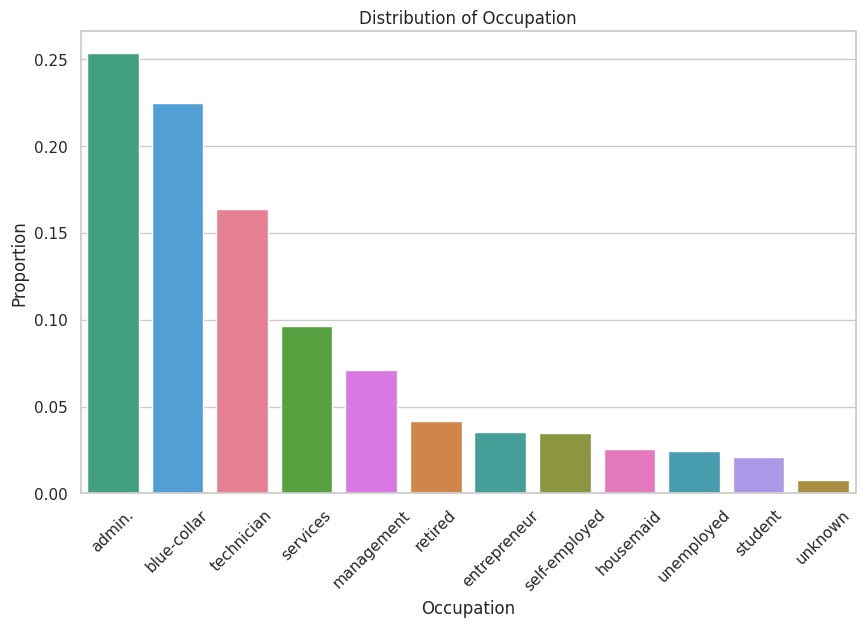

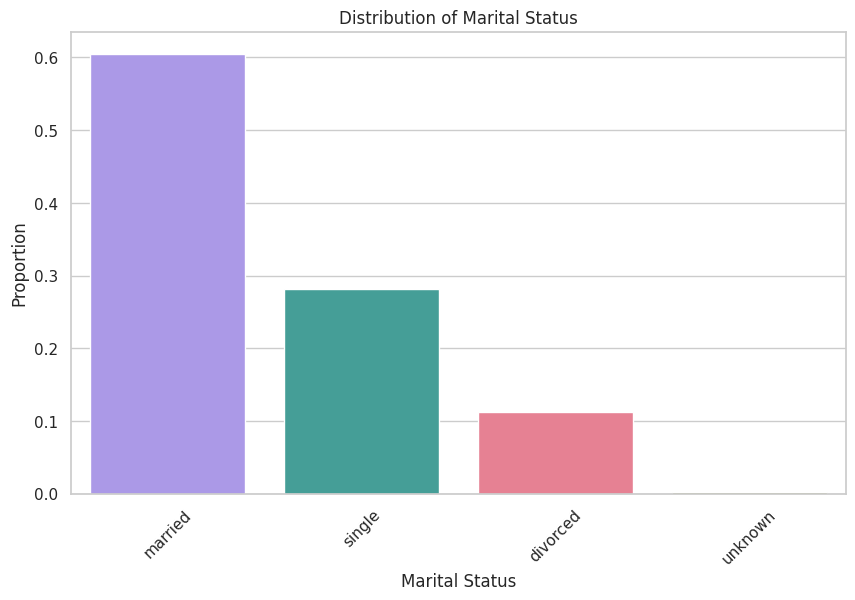

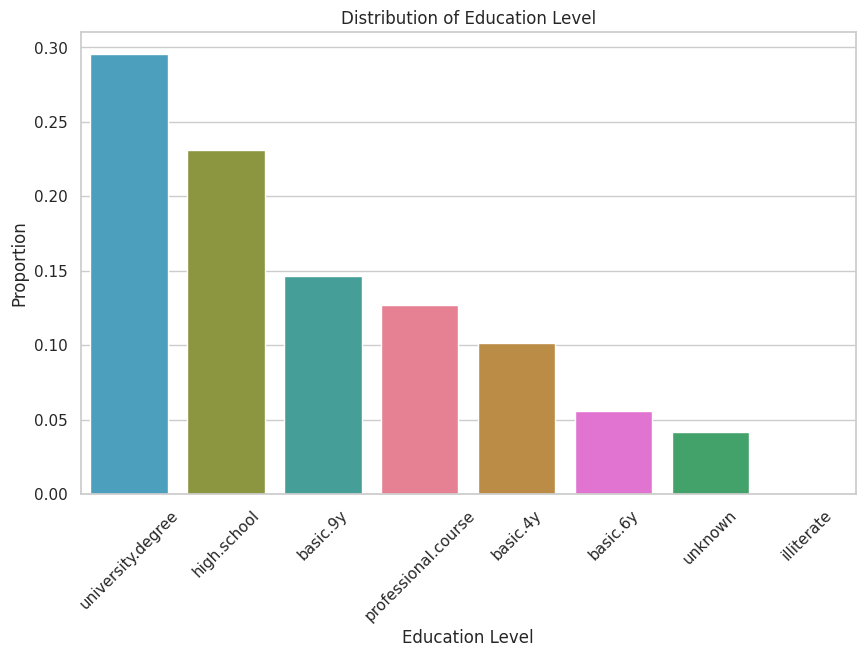

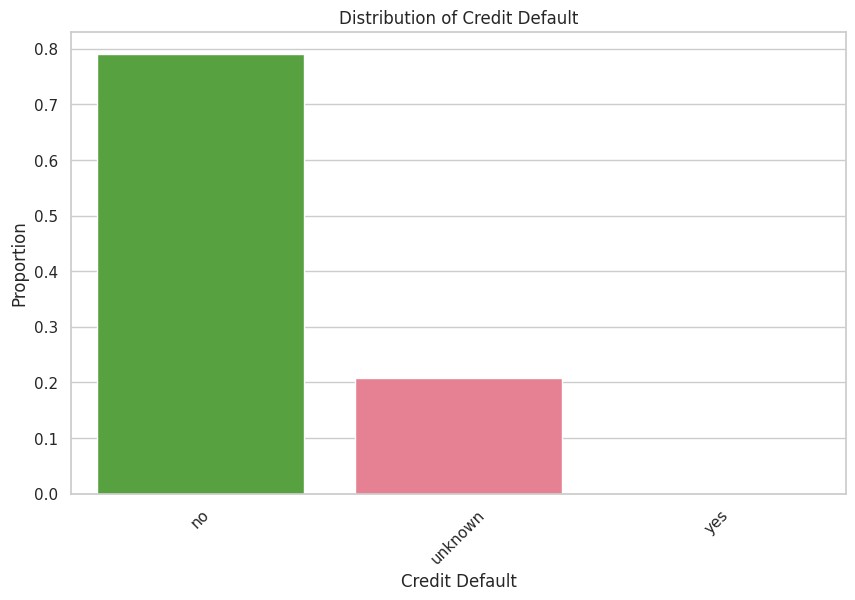

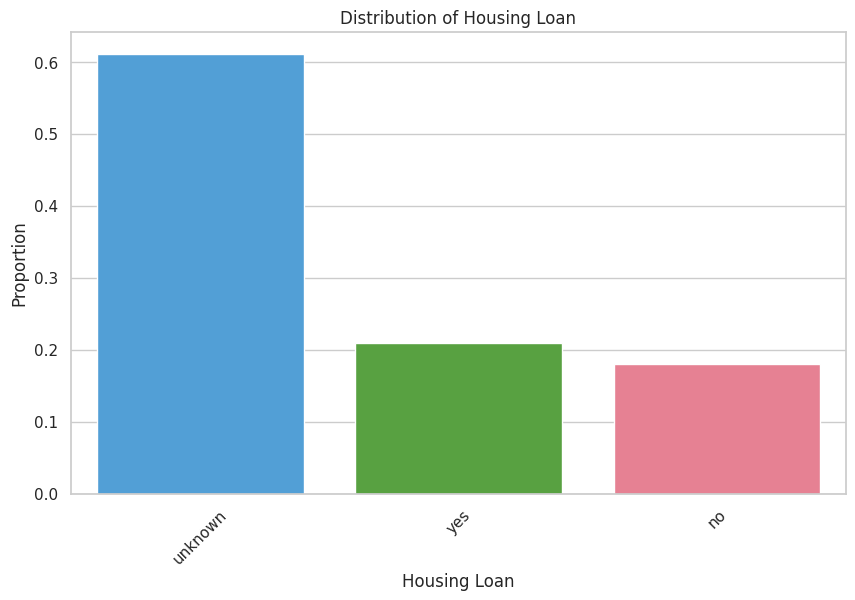

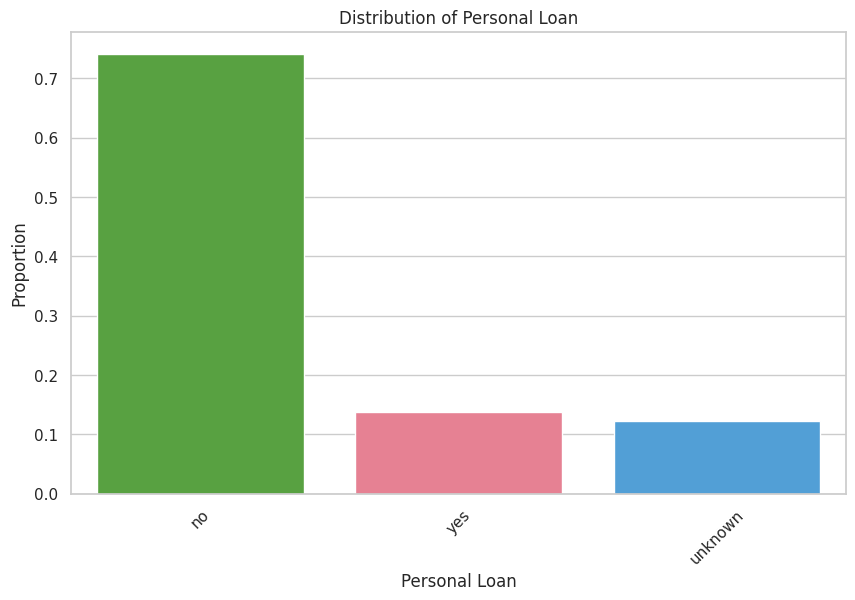

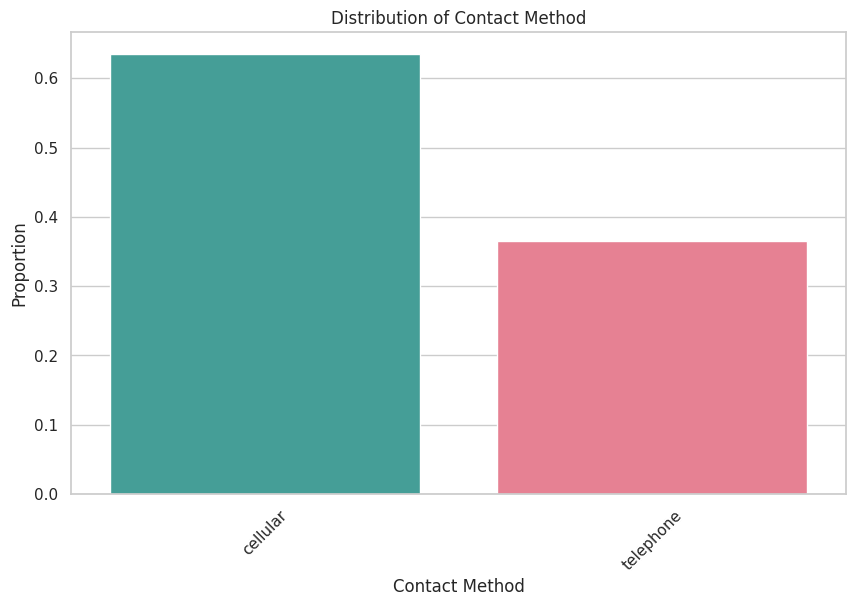

In [ ]:
# Categorical list
categoricals = ['Occupation', 'Marital Status', 'Education Level',
                'Credit Default', 'Housing Loan', 'Personal Loan', 'Contact Method']

# Plot the distribution of categorical columns with a random color palette for each plot
for col in categoricals:
    plt.figure(figsize=(10, 6))
    palette = sns.color_palette("husl", len(df[col].unique()))
    value_counts = df[col].value_counts(normalize=True).sort_values(ascending=False)
    sns.barplot(x=value_counts.index, y=value_counts.values, hue=value_counts.index, dodge=False, palette=np.random.permutation(palette).tolist(), legend=False)
    plt.title(f'Distribution of {col}')
    plt.ylabel('Proportion')
    plt.xticks(rotation=45)
    plt.show()


#### For Numerical

Will use the original dataset and exclude the extreme condition to ensure an accurate understanding of the distribution.

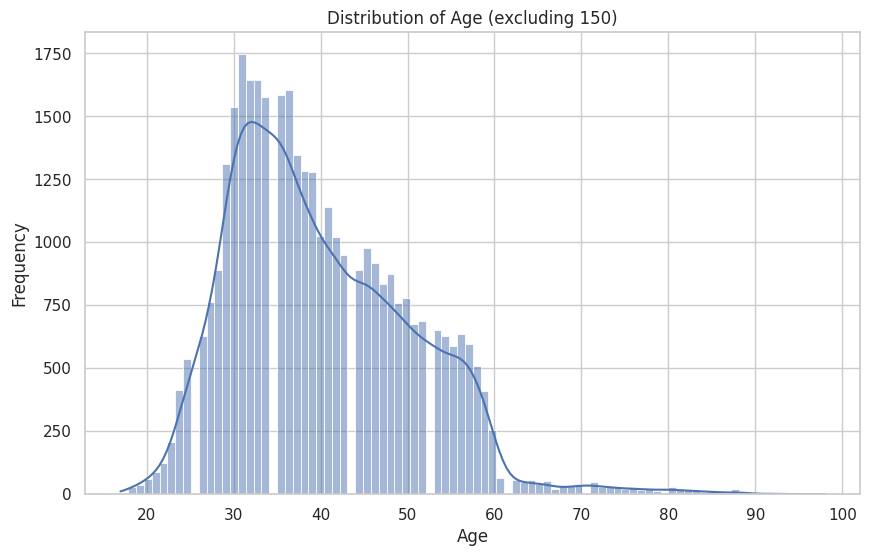

In [ ]:
# To remove the "years" and convert it to float
df_original['Age'] = df_original['Age'].astype(str).str.extract(r'(\d+)').astype(int)

# Create the plot, ignoring the value 150
plt.figure(figsize=(10, 6))
# Using the loaded original dataframe excluding the 150 years.
sns.histplot(df_original[df_original['Age'] != 150]['Age'], kde=True)
plt.title('Distribution of Age (excluding 150)')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


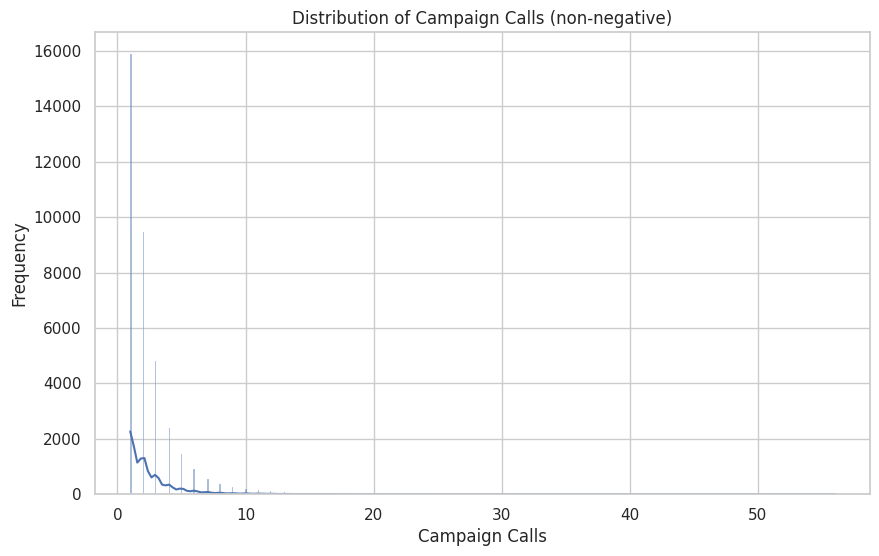

In [ ]:
# Plot the distribution of 'Campaign Calls', ignoring negative values
plt.figure(figsize=(10, 6))
sns.histplot(df_original[df_original['Campaign Calls'] >= 0]['Campaign Calls'], kde=True)
plt.title('Distribution of Campaign Calls (non-negative)')
plt.xlabel('Campaign Calls')
plt.ylabel('Frequency')
plt.show()


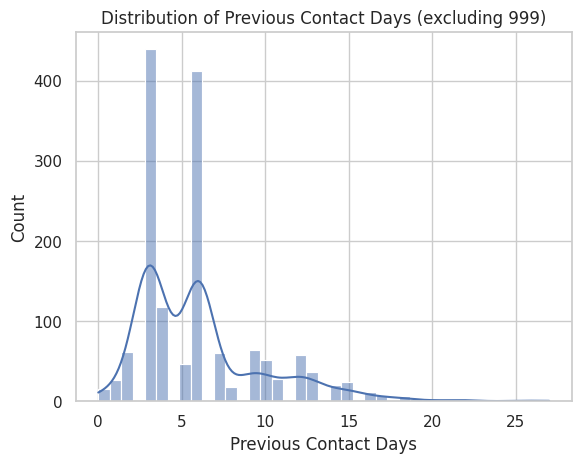

In [ ]:
# Filter out rows where 'Previous Contact Days' is 999
filtered_df = df_original[df_original['Previous Contact Days'] != 999]

# Plot the distribution of 'Previous Contact Days'
sns.histplot(filtered_df['Previous Contact Days'].dropna(), kde=True)
plt.title(f'Distribution of Previous Contact Days (excluding 999)')
plt.show()


### Conclusions

* Numerical features like Age likely showed a right-skewed distribution, with most clients being middle-aged (e.g., **30–50 years**).
* Campaign Calls probably had a skewed distribution with most values being low (**1–3 calls**), but some outliers with high call counts.
* Previous Contact Days had a high frequency of 999 (indicating no previous contact), suggesting it may need transformation (e.g., binary indicator for previous contact).
* Categorical features like Occupation and Education Level revealed common categories (e.g., admin., blue-collar, university.degree).

## 🔁 Step 5: Bivariate Analysis

Explore relationships between features and the target variable (Subscription Status). This helps in understanding which features might be predictive

### For Categorical

<Figure size 1000x600 with 0 Axes>

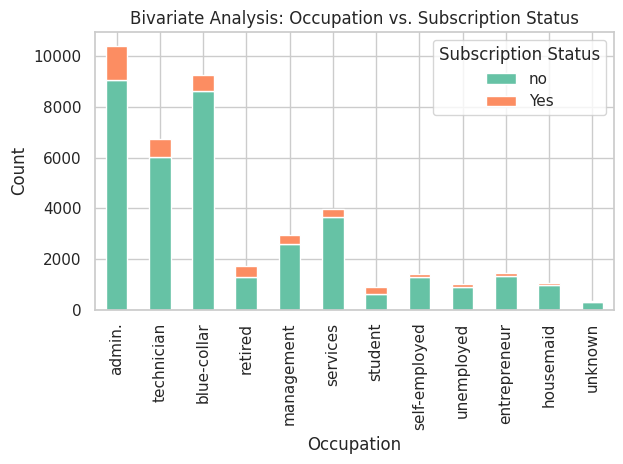

<Figure size 1000x600 with 0 Axes>

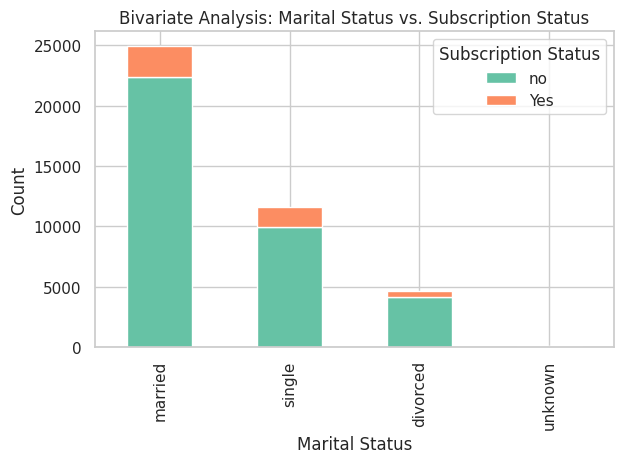

<Figure size 1000x600 with 0 Axes>

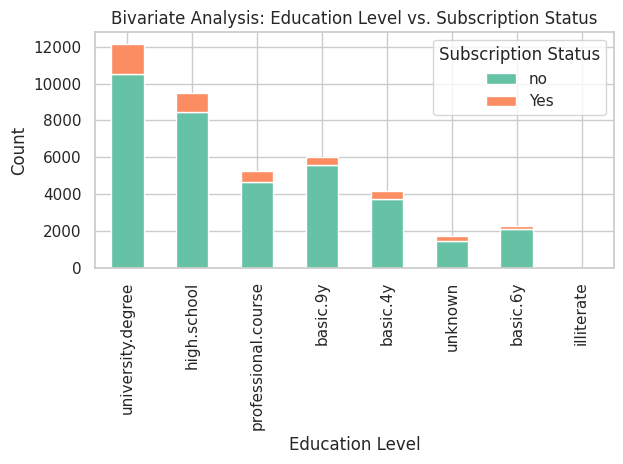

<Figure size 1000x600 with 0 Axes>

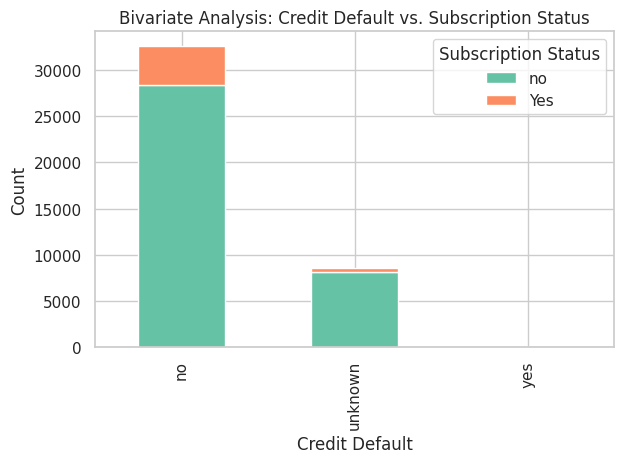

<Figure size 1000x600 with 0 Axes>

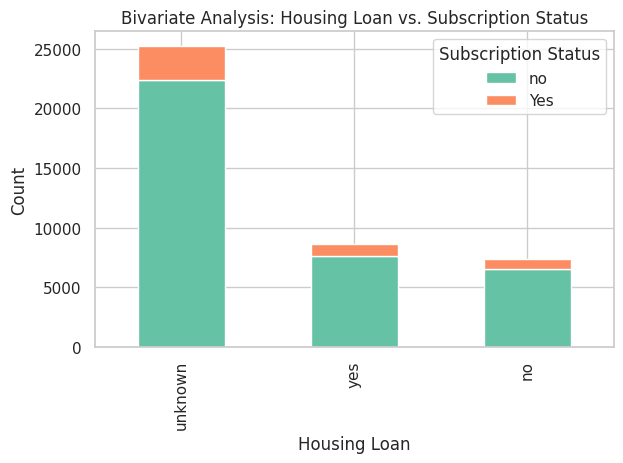

<Figure size 1000x600 with 0 Axes>

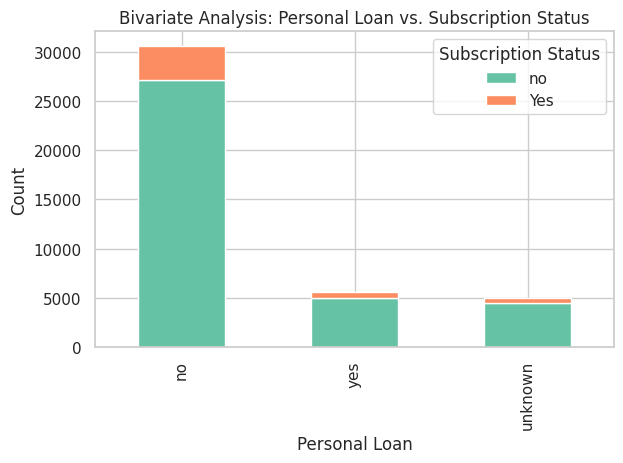

<Figure size 1000x600 with 0 Axes>

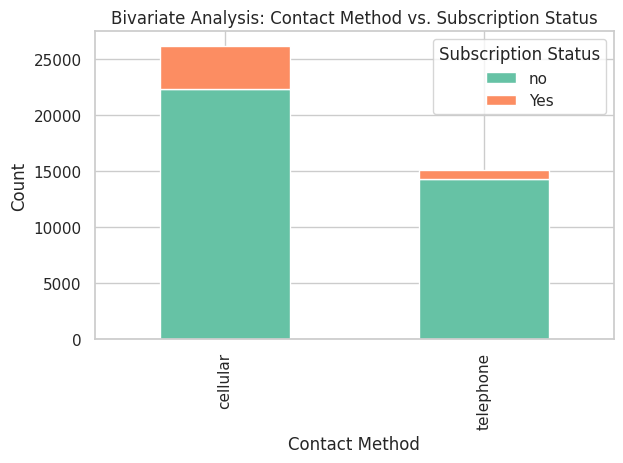

<Figure size 1000x600 with 0 Axes>

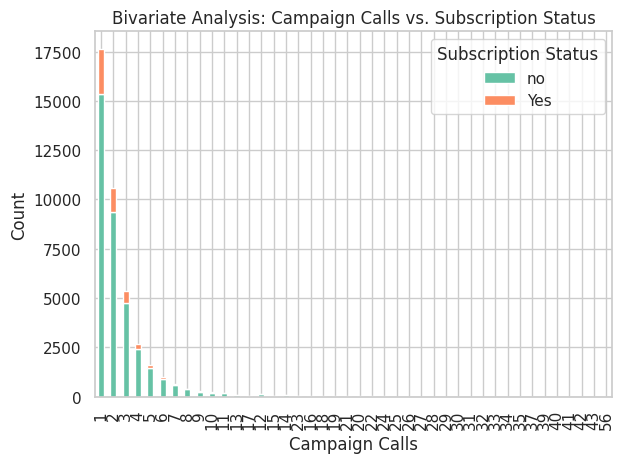

In [ ]:
# Categorical list, including 'Campaign Calls' though it is numerical
categoricals = ['Occupation', 'Marital Status', 'Education Level',
                'Credit Default', 'Housing Loan', 'Personal Loan',
                'Contact Method', 'Campaign Calls']

# Bar plots: Categorical vs Target with random color palette and rotated x-axis labels
for col in categoricals:
    plt.figure(figsize=(10, 6))
    bivariate_counts = df.groupby([col, 'Subscription Status'])['Subscription Status'].count().unstack()
    bivariate_counts = bivariate_counts.fillna(0) #fill nan with 0
    bivariate_counts['Yes'] = bivariate_counts['yes']
    bivariate_counts = bivariate_counts.sort_values(by='Yes', ascending=False)
    bivariate_counts = bivariate_counts.drop('yes',axis=1)

    # Plot the bar chart
    bivariate_counts.plot(kind='bar', stacked=True, color=sns.color_palette("Set2"))
    plt.title(f'Bivariate Analysis: {col} vs. Subscription Status')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.legend(title='Subscription Status')
    plt.tight_layout()
    plt.show()


### Age Distribution

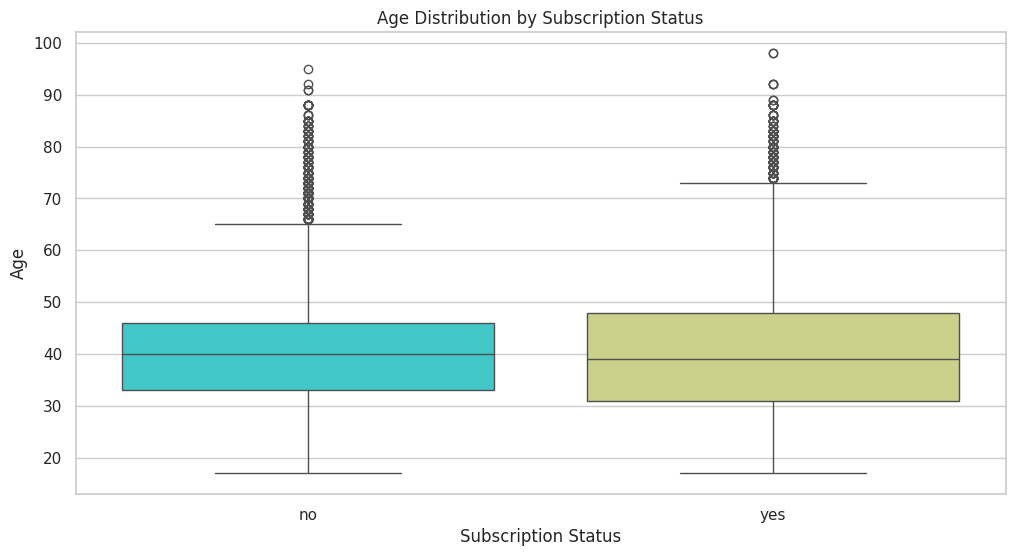

In [ ]:
# Box plot of 'Age' and 'Subscription Status'
plt.figure(figsize=(12, 6))
sns.boxplot(x='Subscription Status', y='Age', data=df, palette="rainbow", hue='Subscription Status')
plt.title('Age Distribution by Subscription Status')
plt.xlabel('Subscription Status')
plt.ylabel('Age')
plt.show()


### Previous Contact Days

Number of days that passed since the client was last contacted in a previous
campaign (999 means no prior contact). Apply special handling for the 999 case and create a plot to check for any significance.

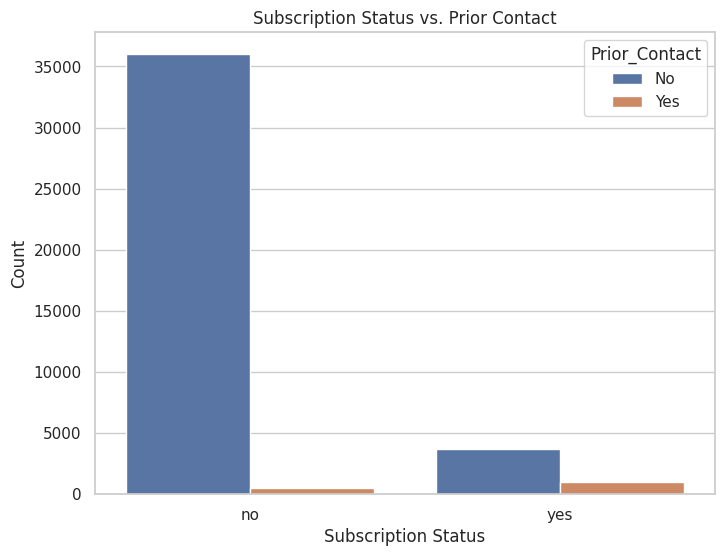

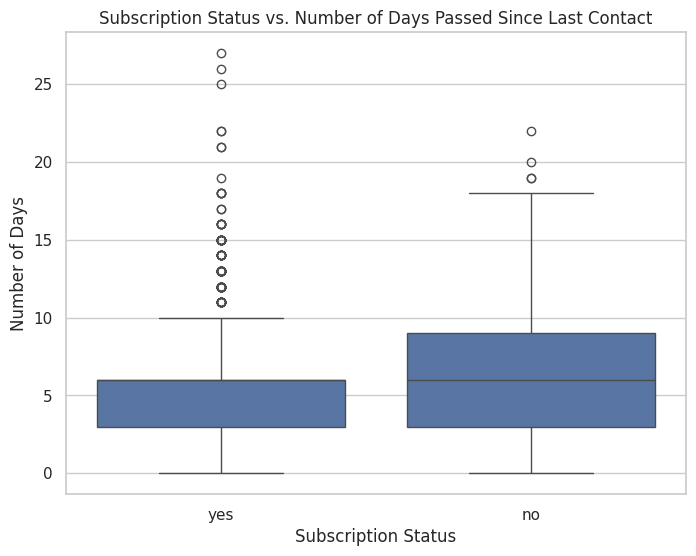

In [ ]:
# 'Previous Contact Days' had special meaning on 999. Number of days that passed since the client was last contacted in a previous
# campaign (999 means no prior contact).

# Filter out rows where 'Previous Contact Days' is 999
no_prior_contact = df[df['Previous Contact Days'] == 999]
prior_contact = df[df['Previous Contact Days'] != 999]

# Plot 1: Subscription Status vs. Prior Contact (Yes/No)
plt.figure(figsize=(8, 6))
sns.countplot(x='Subscription Status', data=pd.concat([no_prior_contact.assign(Prior_Contact='No'), prior_contact.assign(Prior_Contact='Yes')]), hue='Prior_Contact')
plt.title('Subscription Status vs. Prior Contact')
plt.xlabel('Subscription Status')
plt.ylabel('Count')
plt.show()

# Plot 2: Subscription Status vs. Number of Days Passed Since Last Contact
plt.figure(figsize=(8, 6))
sns.boxplot(x='Subscription Status', y='Previous Contact Days', data=prior_contact)
plt.title('Subscription Status vs. Number of Days Passed Since Last Contact')
plt.xlabel('Subscription Status')
plt.ylabel('Number of Days')
plt.show()


### Conclusions

* Features like Education Level, Contact Method, or Previous Contact Days likely showed significant associations with Subscription Status. For example, clients with **higher education or contacted via cellular methods may have higher subscription rates**.
* Numerical features like Age or Campaign Calls may have different distributions for yes vs. no subscriptions, with **younger clients or those with fewer calls potentially more likely to subscribe**.


## 🎶 Step 6: Multivariate Analysis

Examining relationships between three or more variables.

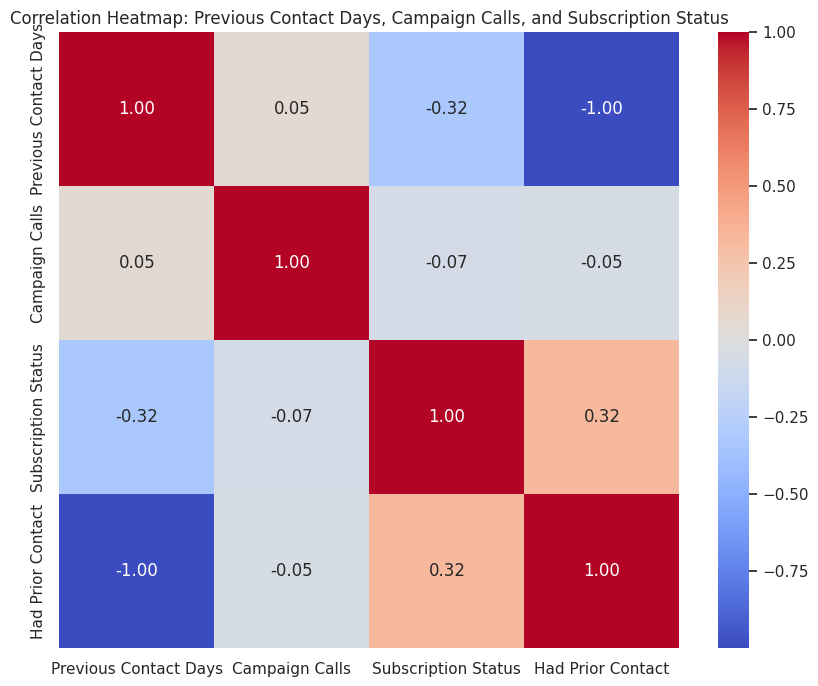

In [ ]:
# 'Previous Contact Days' had special meaning on 999. Number of days that passed since the client was last contacted in a previous
# campaign (999 means no prior contact).

# Create a new DataFrame with 'Previous Contact Days' filtered
filtered_df = df[df['Previous Contact Days'] != 999]

# Instead of replacing 999 with a string, create a new binary column to represent prior contact
df['Had Prior Contact'] = (df['Previous Contact Days'] != 999).astype(int) # 1 if had prior contact, 0 otherwise

# Convert 'Subscription Status' to numerical representation (1 for 'yes', 0 for 'no')
df['Subscription Status'] = df['Subscription Status'].map({'yes': 1, 'no': 0})

# Create the heatmap using the original 'Previous Contact Days' for numerical correlation and the new binary column
plt.figure(figsize=(10, 8))
sns.heatmap(df[['Previous Contact Days', 'Campaign Calls', 'Subscription Status', 'Had Prior Contact']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap: Previous Contact Days, Campaign Calls, and Subscription Status')
plt.show()

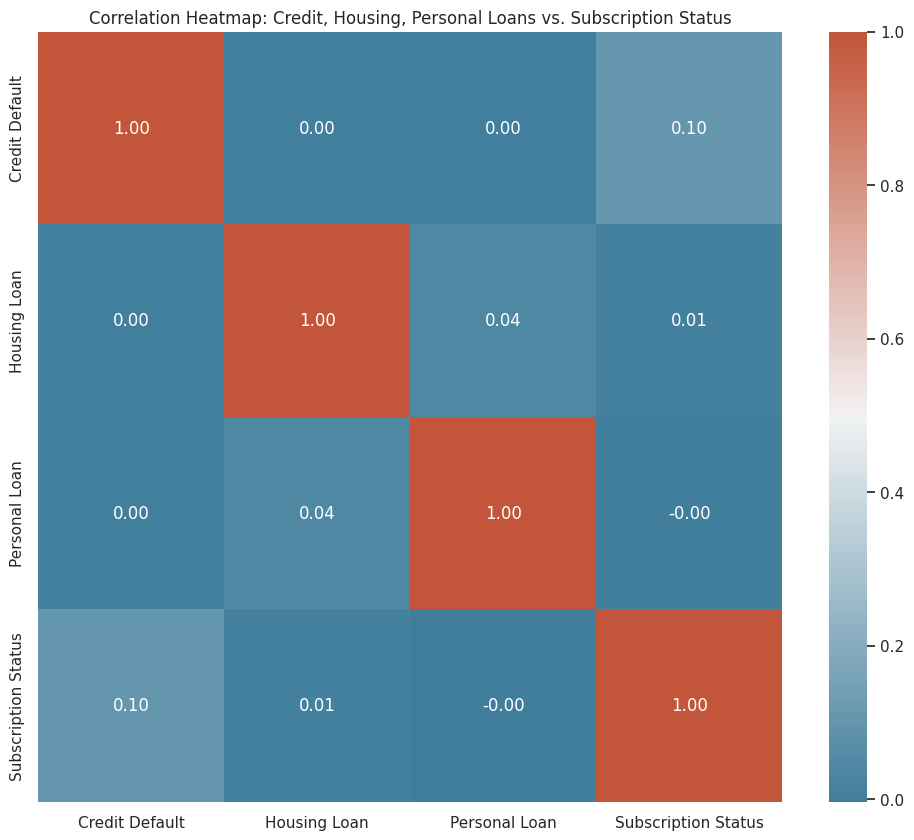

In [ ]:
# Convert 'Credit Default', 'Housing Loan', 'Personal Loan' to numerical
mapping = {'yes': 1, 'no': 0, 'unknown': -1}
for col in ['Credit Default', 'Housing Loan', 'Personal Loan']:
    df[col] = df[col].map(mapping)

# Define a custom colormap
custom_cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df[['Credit Default', 'Housing Loan', 'Personal Loan', 'Subscription Status']].corr(), annot=True, cmap=custom_cmap, fmt=".2f")
plt.title('Correlation Heatmap: Credit, Housing, Personal Loans vs. Subscription Status')
plt.show()


### Conclusion

* Correlation analysis likely revealed **weak correlations** among numerical features, indicating no severe multicollinearity but highlighting key predictors.

## 📌 Step 7: Summary Insights
- Subscription rate overall
  - Expected Statistic: Low percentage of yes (e.g., 10–15%).
  - Interpretation: The low rate confirms the dataset’s imbalance, typical for bank marketing where term deposit subscriptions are rare.
  - Impact: Models must prioritize metrics like precision, recall, or F1-score for the yes class over accuracy, which can be misleading due to imbalance.
- Feature patterns with highest positive response
  - Expected Statistic: Higher subscription rates for specific groups (e.g., university.degree, cellular contact).
  - Interpretation: Certain demographics or campaign strategies are more effective, guiding feature selection and marketing strategies.
  - Impact: These features are retained and emphasized in modeling. Insights can inform business decisions, like targeting educated clients or using cellular contacts.
- Suggestions for next step: modeling and encoding
  - Expected Statistic: Suggestions for encoding and modeling.
  - Interpretation: Categorical encoding (e.g., one-hot) is needed for features like Occupation. Imbalance handling and classification algorithms are recommended.
  - Impact: Proper encoding ensures compatibility with machine learning algorithms. Model choice (e.g., random forests for non-linear relationships) and imbalance techniques improve predictive performance.